# 02 · Two Coins

The canonical discrete EM problem (Do & Batzoglou, *Nature Biotechnology*, 2008),
small enough to trace by hand.

You have two biased coins, **A** and **B**. Someone runs a series of experiments: each
time they secretly pick a coin, flip it `n` times, and record only the number of heads
— never which coin they used. From these flip-counts alone, recover each coin's bias
**and** which coin produced each series.

Same bind as notebook 01: the coin identities are the hidden labels, the biases are the
parameters, and you have neither. EM bootstraps between them.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np


def _repo_root() -> Path:
    here = Path.cwd()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").exists():
            return cand
    return here


ROOT = _repo_root()
FIG_DIR = ROOT / "outputs" / "figures"
DATA_DIR = ROOT / "outputs" / "data"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


def _jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj


def savefig(fig, name):
    """Save a matplotlib figure as outputs/figures/<name>.png."""
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"figure -> {path.relative_to(ROOT)}")
    return path


def savejson(name, obj):
    """Save textual/numerical content as outputs/data/<name>.json."""
    path = DATA_DIR / f"{name}.json"
    path.write_text(json.dumps(_jsonable(obj), indent=2))
    print(f"data   -> {path.relative_to(ROOT)}")
    return path


plt.rcParams["figure.figsize"] = (7, 4.2)
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(42)


## The data

Each experiment is a count of heads out of `n_flips`. We plant the truth so we can
check recovery later.


In [2]:
from src.datasets.mixtures import make_two_coins

PLANTED = {"biases": [0.80, 0.35], "weights": [0.5, 0.5], "n_flips": 12, "n_experiments": 300, "seed": 1}

heads, true_coin, truth = make_two_coins(
    PLANTED["n_experiments"], PLANTED["n_flips"], PLANTED["biases"],
    weights=PLANTED["weights"], seed=PLANTED["seed"],
)

print("first 10 experiments (heads out of 12):", heads[:10].tolist())
savejson("nb02_inputs", {
    "description": "Planted two-coins experiment for notebook 02.",
    "planted_truth": PLANTED,
    "head_counts": heads,
    "head_counts_first10": heads[:10],
})


first 10 experiments (heads out of 12): [3, 4, 10, 4, 10, 9, 7, 10, 6, 12]
data   -> outputs/data/nb02_inputs.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb02_inputs.json')

## One E-step, by hand

Start from a wild guess: `θA = 0.60`, `θB = 0.50`. For a series with `h` heads out of
`n` flips, the likelihood under a coin with bias `θ` is proportional to
`θ**h · (1-θ)**(n-h)` (the binomial coefficient cancels in the ratio). The
**responsibility** of coin A for that series is

> `r_A = wA·L_A / (wA·L_A + wB·L_B)`

a soft label in `[0, 1]`. Let's compute it for the first six series.


 heads         L_A         L_B    resp_A    resp_B
     3   5.662e-05   2.441e-04     0.188     0.812
     4   8.493e-05   2.441e-04     0.258     0.742
    10   9.675e-04   2.441e-04     0.798     0.202
     4   8.493e-05   2.441e-04     0.258     0.742
    10   9.675e-04   2.441e-04     0.798     0.202
     9   6.450e-04   2.441e-04     0.725     0.275
figure -> outputs/figures/nb02_first_estep.png
data   -> outputs/data/nb02_estep_trace.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb02_estep_trace.json')

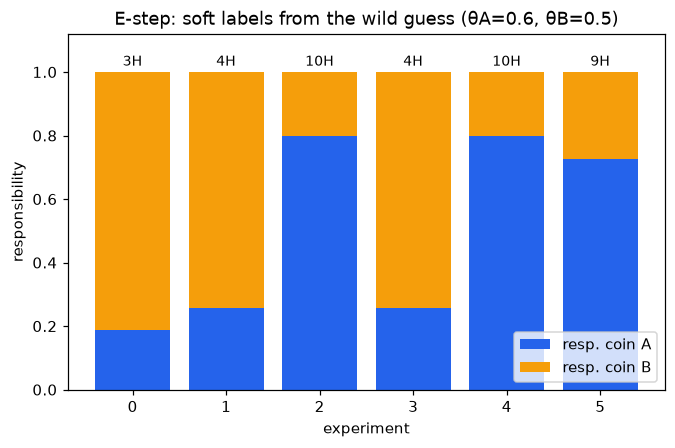

In [3]:
n = PLANTED["n_flips"]
guess = {"thetaA": 0.60, "thetaB": 0.50, "wA": 0.5, "wB": 0.5}

def coin_likelihood(h, theta, n):
    return theta**h * (1 - theta)**(n - h)

h6 = heads[:6]
LA = coin_likelihood(h6, guess["thetaA"], n)
LB = coin_likelihood(h6, guess["thetaB"], n)
rA = guess["wA"] * LA / (guess["wA"] * LA + guess["wB"] * LB)

print(f"{'heads':>6}{'L_A':>12}{'L_B':>12}{'resp_A':>10}{'resp_B':>10}")
trace = []
for hh, la, lb, ra in zip(h6, LA, LB, rA):
    print(f"{hh:>6}{la:>12.3e}{lb:>12.3e}{ra:>10.3f}{1 - ra:>10.3f}")
    trace.append({"heads": int(hh), "L_A": float(la), "L_B": float(lb),
                  "resp_A": float(ra), "resp_B": float(1 - ra)})

fig, ax = plt.subplots()
idx = np.arange(len(h6))
ax.bar(idx, rA, color="#2563eb", label="resp. coin A")
ax.bar(idx, 1 - rA, bottom=rA, color="#f59e0b", label="resp. coin B")
for i, hh in enumerate(h6):
    ax.text(i, 1.02, f"{hh}H", ha="center", fontsize=9)
ax.set_xlabel("experiment"); ax.set_ylabel("responsibility"); ax.set_ylim(0, 1.12)
ax.set_title("E-step: soft labels from the wild guess (θA=0.6, θB=0.5)")
ax.legend(loc="lower right")
savefig(fig, "nb02_first_estep")
savejson("nb02_estep_trace", {"guess": guess, "n_flips": n, "trace_first6": trace})


## One M-step, by hand

Given the responsibilities for **every** series, re-estimate each coin's bias as a
responsibility-weighted head rate:

> `θA = Σ r_A·heads / Σ r_A·n`

A series that coin A is 80% responsible for contributes 80% of its heads to A's estimate.


In [4]:
LA_all = coin_likelihood(heads, guess["thetaA"], n)
LB_all = coin_likelihood(heads, guess["thetaB"], n)
rA_all = guess["wA"] * LA_all / (guess["wA"] * LA_all + guess["wB"] * LB_all)

thetaA_new = (rA_all * heads).sum() / (rA_all * n).sum()
thetaB_new = ((1 - rA_all) * heads).sum() / ((1 - rA_all) * n).sum()
print(f"after ONE EM step:  θA {guess['thetaA']:.2f} -> {thetaA_new:.3f}   θB {guess['thetaB']:.2f} -> {thetaB_new:.3f}")
savejson("nb02_mstep_trace", {
    "before": {"thetaA": guess["thetaA"], "thetaB": guess["thetaB"]},
    "after_one_step": {"thetaA": float(thetaA_new), "thetaB": float(thetaB_new)},
})


after ONE EM step:  θA 0.60 -> 0.708   θB 0.50 -> 0.442
data   -> outputs/data/nb02_mstep_trace.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb02_mstep_trace.json')

## Run it to convergence

The library's `TwoCoinsEM` repeats E and M until the log-likelihood stops improving.
It recovers both biases and the log-likelihood climbs monotonically.


figure -> outputs/figures/nb02_convergence.png
planted biases  : [0.8, 0.35]
recovered biases: [0.813, 0.365]
data   -> outputs/data/nb02_results.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb02_results.json')

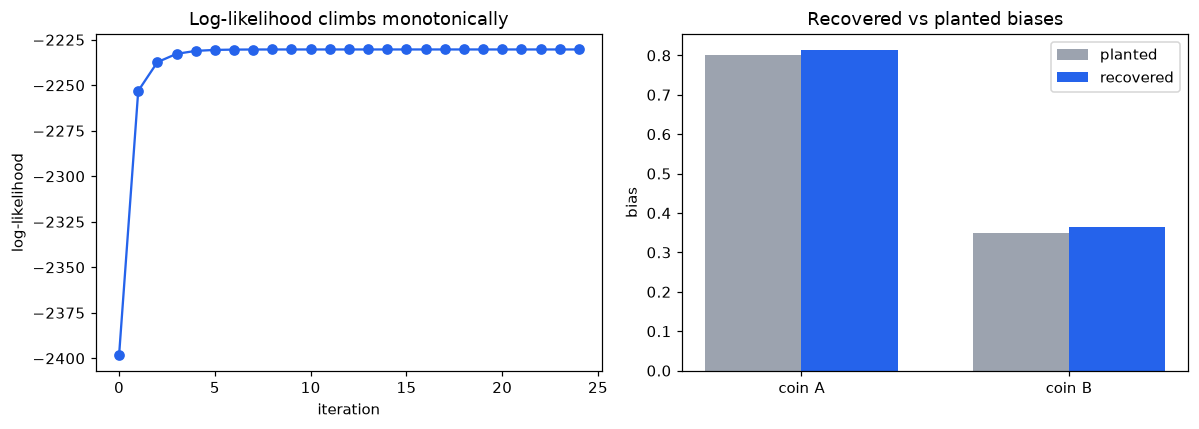

In [5]:
from src.em.two_coins import TwoCoinsEM

model = TwoCoinsEM(2, n_init=5, random_state=0).fit(heads, n)
order = np.argsort(model.biases_)[::-1]   # high-bias coin first, to match planting
rec = model.biases_[order]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(model.loglik_history_, marker="o", color="#2563eb")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("log-likelihood")
axes[0].set_title("Log-likelihood climbs monotonically")

labels = ["coin A", "coin B"]
xp = np.arange(2)
axes[1].bar(xp - 0.18, PLANTED["biases"], width=0.36, label="planted", color="#9ca3af")
axes[1].bar(xp + 0.18, rec, width=0.36, label="recovered", color="#2563eb")
axes[1].set_xticks(xp); axes[1].set_xticklabels(labels)
axes[1].set_ylabel("bias"); axes[1].set_title("Recovered vs planted biases"); axes[1].legend()
fig.tight_layout()
savefig(fig, "nb02_convergence")

print("planted biases  :", PLANTED["biases"])
print("recovered biases:", np.round(rec, 3).tolist())
savejson("nb02_results", {
    "planted_biases": PLANTED["biases"],
    "recovered_biases": rec,
    "recovered_weights": model.weights_[order],
    "n_iterations": int(model.loglik_history_.size - 1),
    "final_log_likelihood": model.log_likelihood_,
    "loglik_history": model.loglik_history_,
    "responsibilities_first6": model.responsibilities_[:6],
})


## Takeaway

With no distributions to hide behind, the two steps are bare: the **E-step** turns the
current biases into soft labels; the **M-step** turns the soft labels into better biases.
Alternate, and both sharpen together until they lock onto the truth.

**Next:** `03_gaussian_mixture_from_scratch` — the same loop on continuous data, built
line by line, recovering means, covariances, and weights.


In [6]:
savejson("nb02_narrative", {
    "title": "Two Coins",
    "problem": "Recover two coin biases and the hidden coin-of-origin from flip-counts alone.",
    "e_step": "Responsibility that each series came from each coin (binomial kernel, soft label).",
    "m_step": "Re-estimate each bias as a responsibility-weighted head rate.",
    "figures": {
        "nb02_first_estep": "Responsibilities for the first six series after the wild guess.",
        "nb02_convergence": "Monotone log-likelihood and recovered-vs-planted biases.",
    },
})


data   -> outputs/data/nb02_narrative.json


PosixPath('/workspaces/expectation_maximization_101/outputs/data/nb02_narrative.json')